# Capítulo 6 — Optimización del control glucémico

Implementación de las ecuaciones (6.1)–(6.10) con los parámetros de cómputo del Anexo B
(pesos de la función de costo, eventos, nivel de referencia). La trayectoria de referencia
es la del modelo calibrado del Capítulo 4 con los parámetros de la Tabla 6.1.

| Sección | Contenido | Celda |
|---|---|---|
| 6.3 | Descomposición wavelet no decimada (starlet B3) de S(t) — Fig. 6.1 | §1 |
| 6.4 | Operador de atenuación sobre un evento — Fig. 6.2 | §2 |
| 6.5–6.10 | Eventos, re-simulación causal y optimización TPE (sujeto 5) — Figs. 6.3–6.4, 6.10, Tabla 6.2 | §3 |
| 6.11 | Sensibilidad a atenuación uniforme (Fig. 6.5), OPTM y H×C (Figs. 6.7–6.8) | §4 |
| 6.12 | Lectura poblacional en los 20 DBT2 (Tabla 6.3) | §5 |
| 6.13 | Espectro (Fig. 6.11), transformaciones globales de S (Tabla 6.4), ‖v‖ vs HbA1c (Fig. 6.12) | §6 |

In [1]:
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("glucosa").exists():
    os.system("git clone -q https://github.com/aamadioaaa/tesis-glucosa-sdde.git")
    os.chdir("tesis-glucosa-sdde/notebooks")
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from glucosa import datos, sdde, detector, ordinal, espectral, intervencion as iv
from glucosa.forzamiento import forzamiento

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
OUT = datos.carpeta_resultados(6)
N = datos.N_12_DIAS
print("Pesos de la función de costo (6.10):", iv.PESOS_COSTO)


def guardar_panel(fig, ejes, nombre):
    """Guarda uno o varios paneles de una figura compuesta como imagen independiente."""
    from matplotlib.transforms import Bbox
    fig.canvas.draw()
    ejes = ejes if isinstance(ejes, (list, tuple)) else [ejes]
    caja = Bbox.union([a.get_tightbbox(fig.canvas.get_renderer()) for a in ejes]).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(OUT / nombre, dpi=200, bbox_inches=caja.expanded(1.03, 1.05))

SUJ = 5
g = datos.cargar_cgm("DBT2", SUJ, N); p = datos.parametros("DBT2", SUJ)
s = forzamiento(g)
ruido = sdde.ruido_blanco(N)
g_ref = sdde.simular(g, ruido=ruido, **p)
pd.DataFrame([{k: v for k, v in p.items() if k != "filtro_sg"}], index=["DBT2-05"]).to_csv(OUT / "tabla_6_1_parametros_sujeto5.csv", float_format="%.6g")
print("Tabla 6.1 — parámetros del sujeto 5:", {k: round(v, 4) for k, v in p.items() if k != "filtro_sg"},
      f"| Ḡ real = {g.mean():.1f} mg/dL")
print("Trayectoria de referencia:", {k: round(v, 2) for k, v in iv.resumen(g_ref).items()},
      f"| ρ con la señal medida = {np.corrcoef(g_ref, g)[0, 1]:.3f}")

Pesos de la función de costo (6.10): {'w_A': 10.0, 'w_TBR': 100.0, 'w_e': 1.0, 'tau_TBR': 0.02}


Tabla 6.1 — parámetros del sujeto 5: {'alpha': 0.0019, 'tau_d': 67.1282, 'k_f': 1.4684, 'beta_n': 0.19, 'delta_b': 23.1664} | Ḡ real = 161.3 mg/dL
Trayectoria de referencia: {'G_media': np.float64(161.32), 'A1c': np.float64(7.25), 'GMI': np.float64(7.17), 'TIR': np.float64(72.92), 'TAR': np.float64(26.39), 'TBR': np.float64(0.69), 'TBR54': np.float64(0.0), 'hipo_max_h': 1.25} | ρ con la señal medida = 0.842


## 1. Descomposición wavelet no decimada de S(t) (Fig. 6.1)

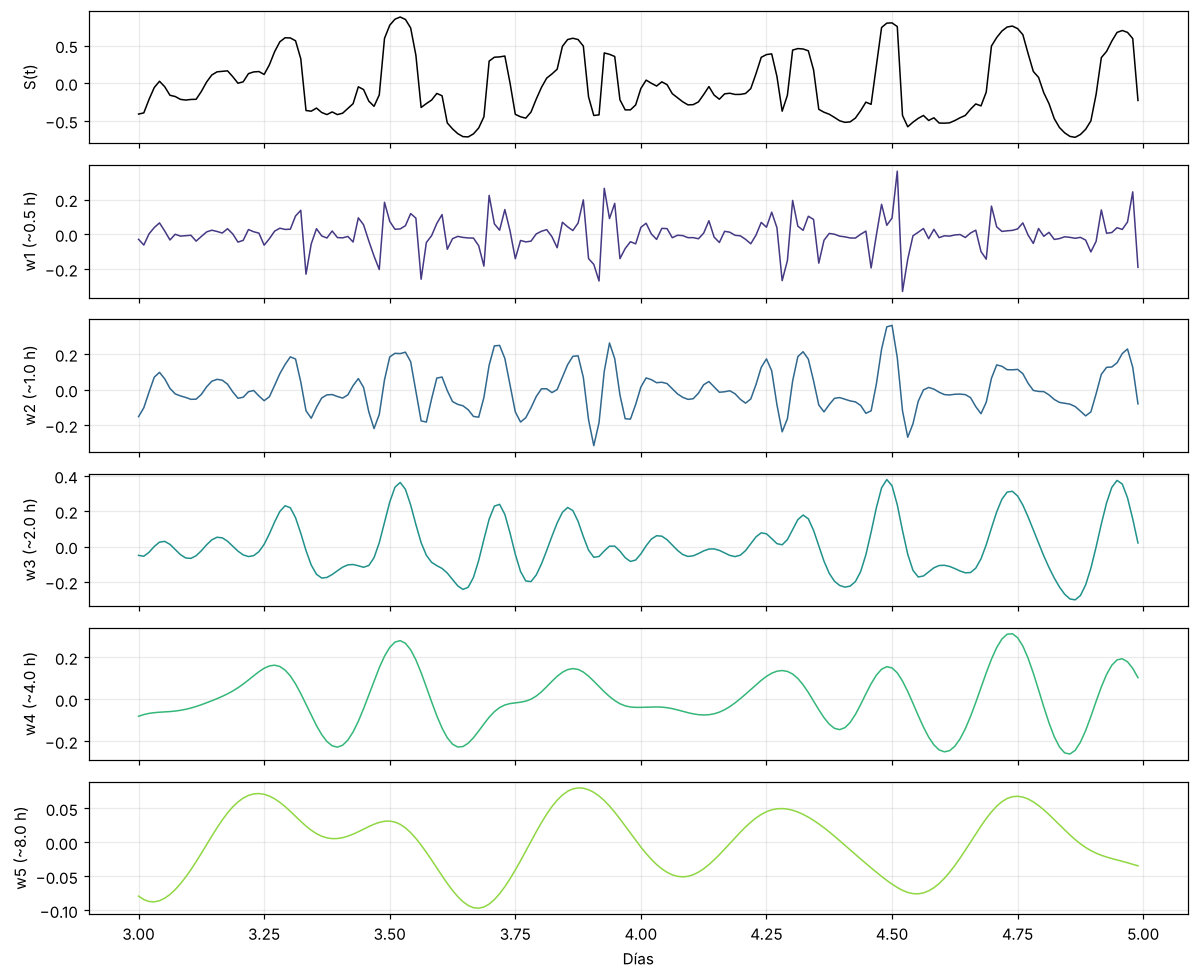

Reconstrucción exacta S = c_J + Σ w_j: True


In [2]:
s_b, detalles = iv.componente_posprandial(s)
t_d = np.arange(N) / 96; sl = slice(96 * 3, 96 * 5)
fig, ax = plt.subplots(6, 1, figsize=(11, 9), sharex=True)
ax[0].plot(t_d[sl], s[sl], "k", lw=1); ax[0].set_ylabel("S(t)")
for j, w in enumerate(detalles, start=1):
    ax[j].plot(t_d[sl], w[sl], color=plt.cm.viridis(j / 6), lw=1); ax[j].set_ylabel(f"w{j} (~{2**j*15/60:.1f} h)")
ax[-1].set_xlabel("Días"); fig.tight_layout(); fig.savefig(OUT / "figura_6_1_starlet.png", dpi=200); plt.show()
print("Reconstrucción exacta S = c_J + Σ w_j:", np.allclose(s, iv.starlet(s)[1] + np.sum(detalles, axis=0)))

## 2. Acción local del operador sobre un evento (Fig. 6.2, ρ_i = 0,25 ilustrativo)

Ventanas compatibles con ingesta sobre la trayectoria de referencia: 28


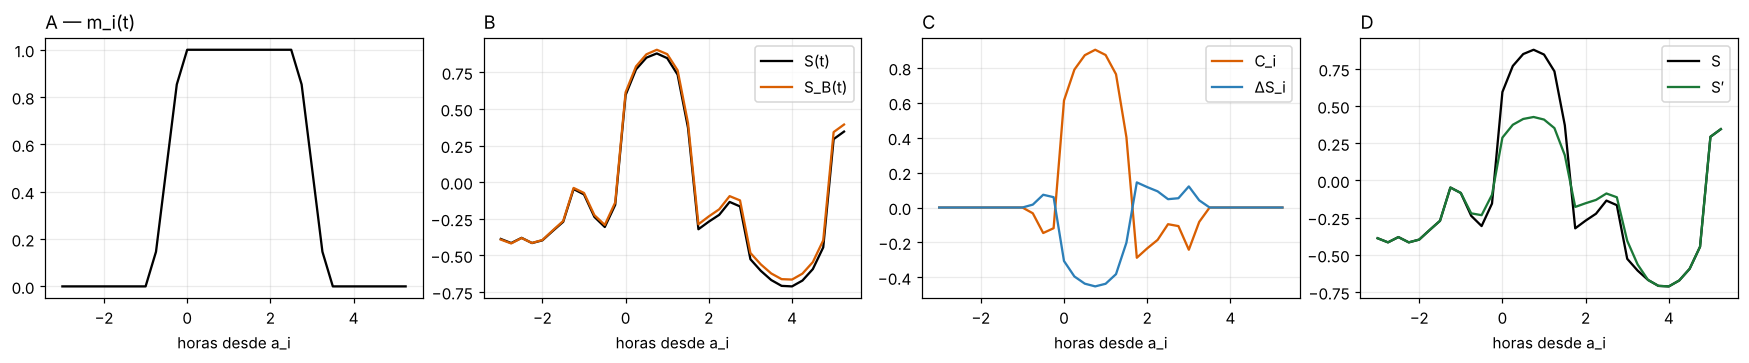

In [3]:
ev_obj = detector.detectar_ingestas(g_ref, s)
eventos = [(e.inicio, e.fin) for e in ev_obj]
print(f"Ventanas compatibles con ingesta sobre la trayectoria de referencia: {len(eventos)}")
a, b = max(eventos, key=lambda ab: np.sum(s_b[ab[0]:ab[1] + 1] ** 2))
m = iv.ventana(N, a, b); c_i = m * s_b; s_mod = iv.atenuar(s, [(a, b)], [0.25], s_b)
sl = slice(a - 12, b + 12); t_h = (np.arange(N)[sl] - a) / 4
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
ax[0].plot(t_h, m[sl], "k"); ax[0].set_title("A — m_i(t)", loc="left")
ax[1].plot(t_h, s[sl], "k", label="S(t)"); ax[1].plot(t_h, s_b[sl], color="#d95f02", label="S_B(t)"); ax[1].legend(); ax[1].set_title("B", loc="left")
ax[2].plot(t_h, c_i[sl], color="#d95f02", label="C_i"); ax[2].plot(t_h, (np.sqrt(.25) - 1) * c_i[sl], color="#2c7fb8", label="ΔS_i"); ax[2].legend(); ax[2].set_title("C", loc="left")
ax[3].plot(t_h, s[sl], "k", label="S"); ax[3].plot(t_h, s_mod[sl], color="#1b7837", label="S′"); ax[3].legend(); ax[3].set_title("D", loc="left")
for x in ax: x.set_xlabel("horas desde a_i")
fig.tight_layout(); fig.savefig(OUT / "figura_6_2_operador.png", dpi=200); plt.show()

## 3. Optimización del caso individual (sujeto 5, objetivo HbA1c eq. ≤ 6,8 %)

In [4]:
R = iv.optimizar(g, p, eventos, a1c_obj=6.8, n_ensayos=250, semilla=42, g_referencia=g_ref)
ref, inter = iv.resumen(R.g_referencia), iv.resumen(R.g_intervenida)
v_ref, v_int = ordinal.norma_estacionaria(R.g_referencia), ordinal.norma_estacionaria(R.g_intervenida)
tabla_62 = pd.DataFrame({"Referencia": [ref["A1c"], ref["GMI"], ref["G_media"], ref["TIR"], ref["TAR"], ref["TBR"], v_ref],
                         "Con intervención": [inter["A1c"], inter["GMI"], inter["G_media"], inter["TIR"], inter["TAR"], inter["TBR"], v_int]},
                        index=["HbA1c eq. ADAG (%)", "GMI (%)", "Glucosa media (mg/dL)", "TIR 70–180 (%)", "TAR >180 (%)", "TBR <70 (%)", "‖v‖ OPTM"])
tabla_62.round(3).to_csv(OUT / "tabla_6_2_sujeto5.csv")
print(f"Energía posprandial: {R.energia_ref.sum():.1f} → {R.energia_final.sum():.1f} u.a. "
      f"({100 * R.energia_final.sum() / R.energia_ref.sum():.0f} % conservado); eventos modificados: "
      f"{np.sum(R.rho < 0.99)}/{len(eventos)}")
tabla_62.round(3)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Energía posprandial: 22.4 → 15.6 u.a. (70 % conservado); eventos modificados: 28/28


,Referencia,Con intervención
HbA1c eq. ADAG (%),7.248,6.788
GMI (%),7.169,6.853
Glucosa media (mg/dL),161.320,148.129
TIR 70–180 (%),72.917,80.556
TAR >180 (%),26.389,18.316
TBR <70 (%),0.694,1.128
‖v‖ OPTM,0.604,0.607


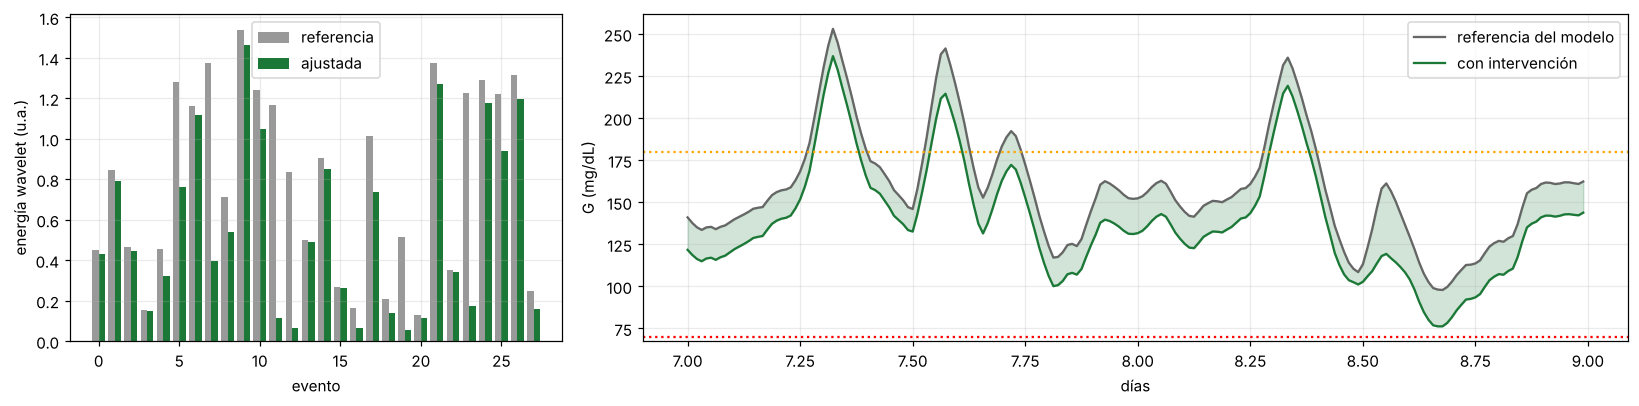

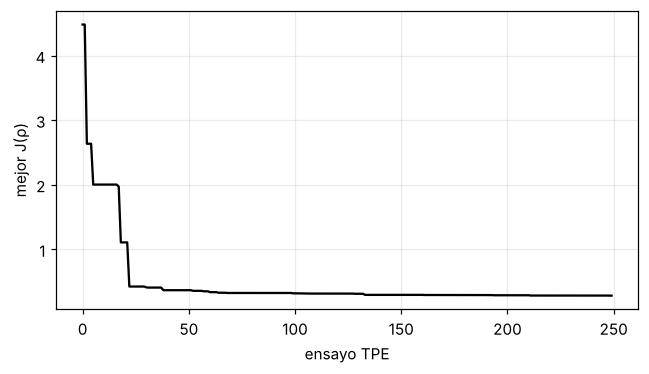

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1, 2]))
x = np.arange(len(eventos))
ax[0].bar(x - .2, R.energia_ref, .4, color="0.6", label="referencia"); ax[0].bar(x + .2, R.energia_final, .4, color="#1b7837", label="ajustada")
ax[0].set(xlabel="evento", ylabel="energía wavelet (u.a.)"); ax[0].legend()
d0 = int(np.argmax([np.sum(R.g_referencia[k:k + 192] - R.g_intervenida[k:k + 192]) for k in range(0, N - 192, 96)]))
sl = slice(96 * d0, 96 * (d0 + 2)); tt = np.arange(N)[sl] / 96
ax[1].plot(tt, R.g_referencia[sl], color="0.4", label="referencia del modelo"); ax[1].plot(tt, R.g_intervenida[sl], color="#1b7837", label="con intervención")
ax[1].fill_between(tt, R.g_intervenida[sl], R.g_referencia[sl], where=R.g_referencia[sl] > R.g_intervenida[sl], color="#1b7837", alpha=.2)
ax[1].axhline(70, color="r", ls=":"); ax[1].axhline(180, color="orange", ls=":"); ax[1].legend(); ax[1].set(xlabel="días", ylabel="G (mg/dL)")
fig.tight_layout(); fig.savefig(OUT / "figuras_6_3_y_6_4.png", dpi=200)
guardar_panel(fig, ax[0], "figura_6_3_energia_eventos.png"); guardar_panel(fig, ax[1], "figura_6_4_trayectorias.png"); plt.show()

plt.figure(figsize=(6, 3.5)); plt.plot(R.historial, color="k"); plt.xlabel("ensayo TPE"); plt.ylabel("mejor J(ρ)")
plt.tight_layout(); plt.savefig(OUT / "figura_6_10_convergencia.png", dpi=200); plt.show()

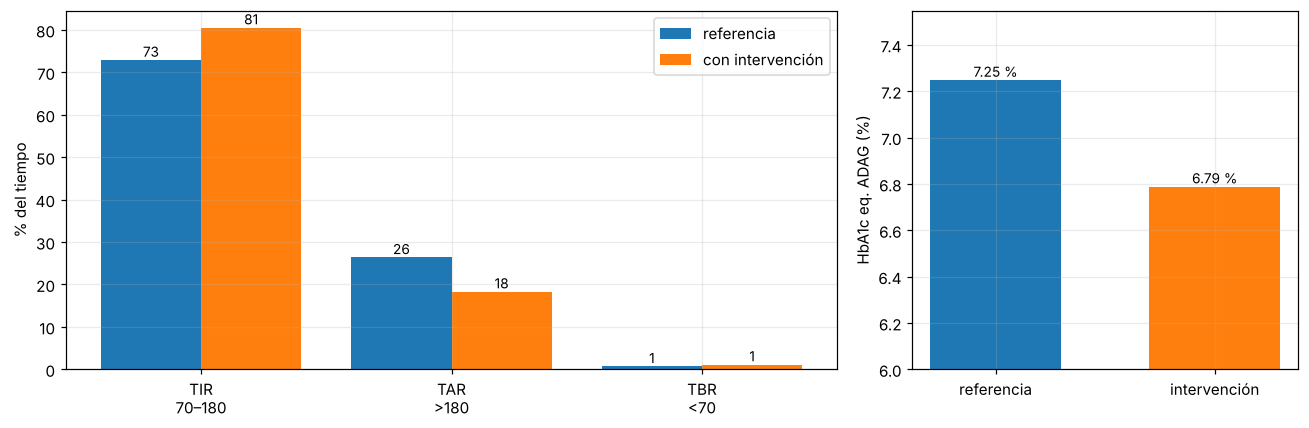

In [6]:
# Figura 6.6 — tiempos en rango y HbA1c equivalente, antes y después
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[2, 1]))
cats = ["TIR", "TAR", "TBR"]; xx = np.arange(3)
b0 = ax[0].bar(xx - .2, [ref[c] for c in cats], .4, color="#1f77b4", label="referencia")
b1 = ax[0].bar(xx + .2, [inter[c] for c in cats], .4, color="#ff7f0e", label="con intervención")
for bb in (b0, b1):
    ax[0].bar_label(bb, fmt="%.0f", fontsize=9)
ax[0].set_xticks(xx, ["TIR\n70–180", "TAR\n>180", "TBR\n<70"]); ax[0].set_ylabel("% del tiempo"); ax[0].legend()
bb = ax[1].bar([0, 1], [ref["A1c"], inter["A1c"]], color=["#1f77b4", "#ff7f0e"], width=.6)
ax[1].bar_label(bb, fmt="%.2f %%", fontsize=9); ax[1].set_xticks([0, 1], ["referencia", "intervención"])
ax[1].set_ylabel("HbA1c eq. ADAG (%)"); ax[1].set_ylim(6.0, max(ref["A1c"], inter["A1c"]) + .3)
fig.tight_layout(); fig.savefig(OUT / "figura_6_6_tiempos_en_rango_a1c.png", dpi=200); plt.show()

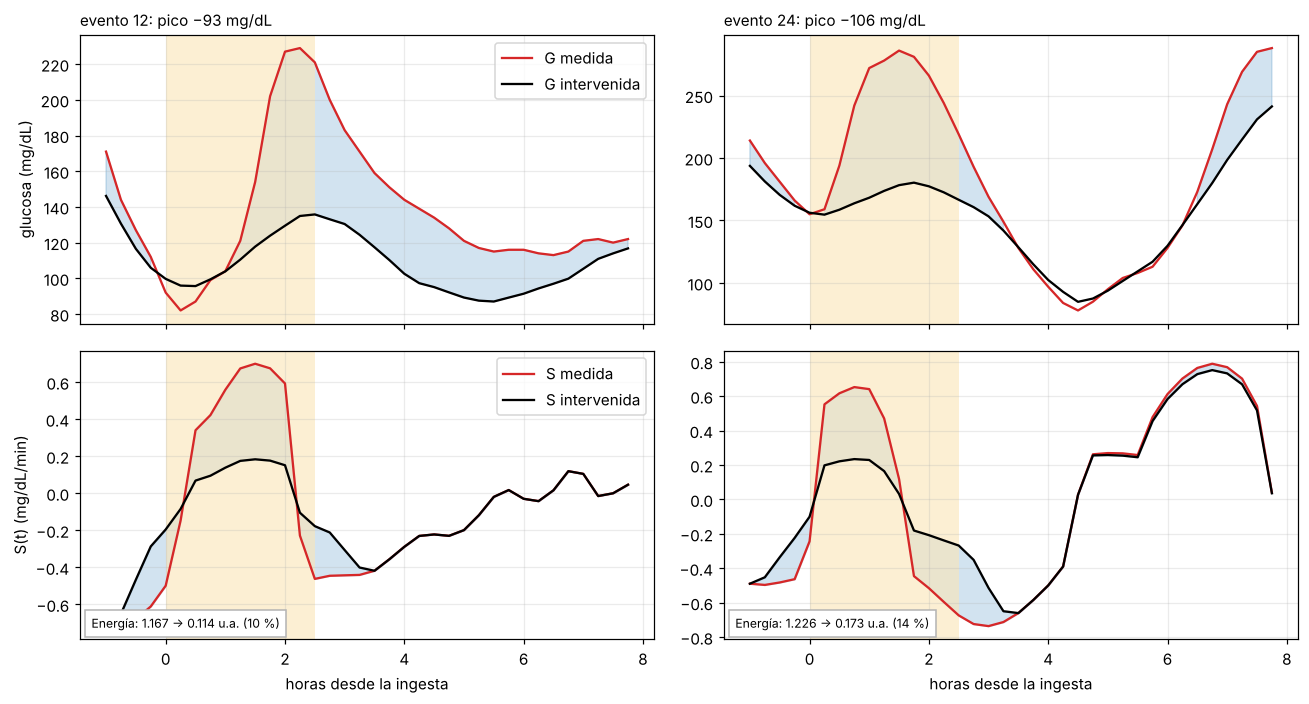

In [7]:
# Figura 6.9 — anatomía de los dos eventos con mayor reducción de energía
red = R.energia_ref - R.energia_final
top = np.argsort(red)[::-1][:2]
fig, ax = plt.subplots(2, 2, figsize=(12, 6.5), sharex="col")
for col, k in enumerate(sorted(top, key=lambda k: R.eventos[k][0])):
    a, b = R.eventos[k]; sl = slice(max(0, a - 4), min(N, a + 32)); th = (np.arange(N)[sl] - a) / 4
    ax[0, col].plot(th, g[sl], color="#d62728", label="G medida"); ax[0, col].plot(th, R.g_intervenida[sl], "k", label="G intervenida")
    ax[0, col].fill_between(th, R.g_intervenida[sl], g[sl], where=g[sl] > R.g_intervenida[sl], color="#1f77b4", alpha=.2)
    ax[0, col].axvspan(0, (b - a) / 4, color="#fbe5b6", alpha=.6, lw=0)
    ax[0, col].set_title(f"evento {k + 1}: pico −{np.max(g[a:b + 1]) - np.max(R.g_intervenida[a:b + 1]):.0f} mg/dL", loc="left", fontsize=10)
    ax[1, col].plot(th, s[sl], color="#d62728", label="S medida"); ax[1, col].plot(th, R.s_intervenido[sl], "k", label="S intervenida")
    ax[1, col].fill_between(th, R.s_intervenido[sl], s[sl], color="#1f77b4", alpha=.2); ax[1, col].axvspan(0, (b - a) / 4, color="#fbe5b6", alpha=.6, lw=0)
    ax[1, col].text(.02, .04, f"Energía: {R.energia_ref[k]:.3f} → {R.energia_final[k]:.3f} u.a. ({100 * R.rho[k]:.0f} %)",
                    transform=ax[1, col].transAxes, fontsize=8, bbox=dict(fc="w", ec="0.7"))
    ax[1, col].set_xlabel("horas desde la ingesta")
ax[0, 0].set_ylabel("glucosa (mg/dL)"); ax[1, 0].set_ylabel("S(t) (mg/dL/min)"); ax[0, 0].legend(); ax[1, 0].legend()
fig.tight_layout(); fig.savefig(OUT / "figura_6_9_anatomia_eventos.png", dpi=200); plt.show()

## 4. Sensibilidad a atenuación uniforme (Fig. 6.5) y organización temporal (Figs. 6.7–6.8)

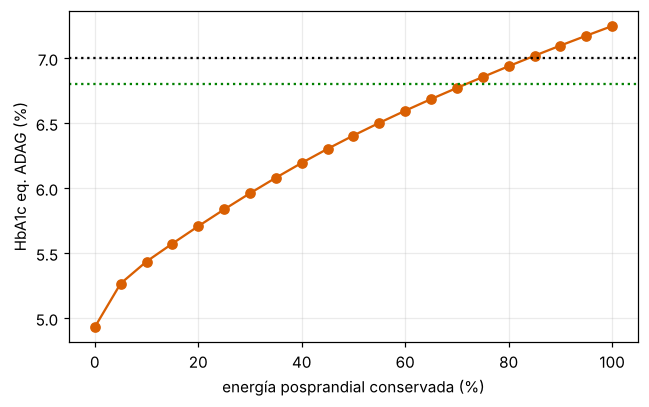

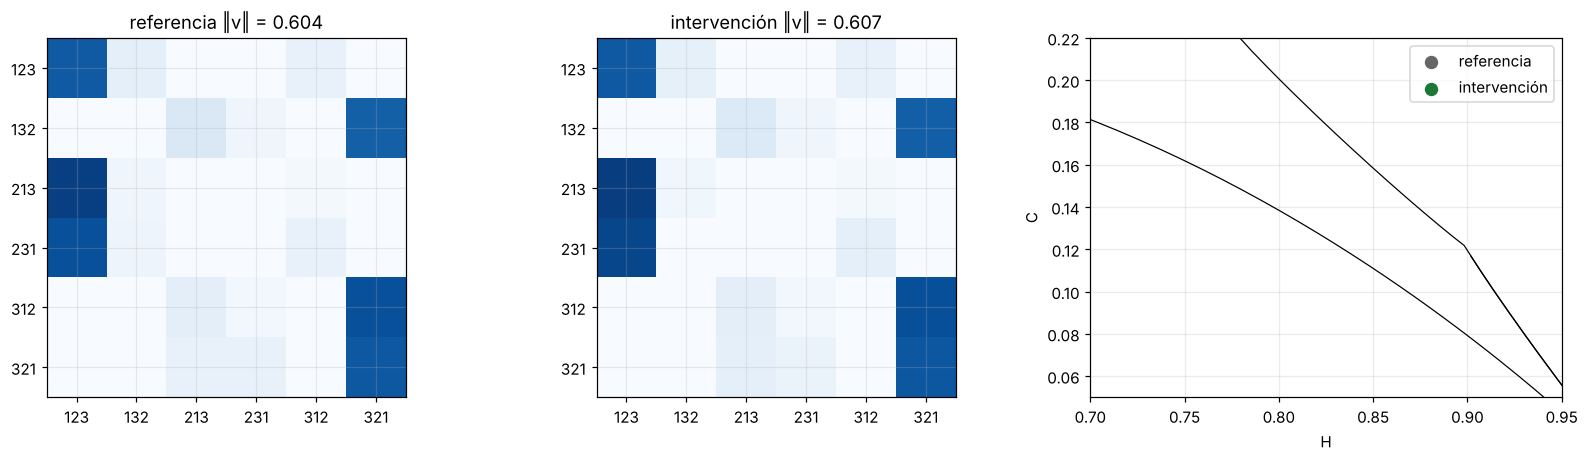

Índice compuesto ν (secuencial): 0.7905694150420949 → 0.7905694150420949


In [8]:
fr = np.linspace(0, 1, 21)
a1c_unif = [iv.a1c_adag(iv.simular_intervencion(g, p, iv.atenuar(s, eventos, [f] * len(eventos), s_b), ruido=ruido).mean()) for f in fr]
plt.figure(figsize=(6, 3.8)); plt.plot(100 * fr, a1c_unif, "o-", color="#d95f02")
plt.axhline(7, color="k", ls=":"); plt.axhline(6.8, color="g", ls=":"); plt.xlabel("energía posprandial conservada (%)")
plt.ylabel("HbA1c eq. ADAG (%)"); plt.tight_layout(); plt.savefig(OUT / "figura_6_5_uniforme.png", dpi=200); plt.show()

M_ref, M_int = ordinal.matrices_optm(R.g_referencia)["secuencial"], ordinal.matrices_optm(R.g_intervenida)["secuencial"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a_, M, tit in [(ax[0], M_ref, f"referencia ‖v‖ = {v_ref:.3f}"), (ax[1], M_int, f"intervención ‖v‖ = {v_int:.3f}")]:
    im = a_.imshow(M, cmap="Blues", vmin=0, vmax=1); a_.set_xticks(range(6), ordinal.NOMBRES_PATRONES); a_.set_yticks(range(6), ordinal.NOMBRES_PATRONES); a_.set_title(tit)
hmin, cmin, hmax, cmax = ordinal.curvas_limite(3)
ax[2].plot(hmax, cmax, "k-", lw=.8); ax[2].plot(hmin, cmin, "k-", lw=.8)
for y, c, l in [(R.g_referencia, "0.4", "referencia"), (R.g_intervenida, "#1b7837", "intervención")]:
    ax[2].scatter(*ordinal.hxc(y), color=c, s=60, label=l)
ax[2].set(xlim=(.7, .95), ylim=(.05, .22), xlabel="H", ylabel="C"); ax[2].legend()
fig.tight_layout(); fig.savefig(OUT / "figuras_6_7_y_6_8_optm_hxc.png", dpi=200)
guardar_panel(fig, [ax[0], ax[1]], "figura_6_7_optm.png"); guardar_panel(fig, ax[2], "figura_6_8_hxc.png"); plt.show()
print("Índice compuesto ν (secuencial):", ordinal.clasificar(R.g_referencia)["secuencial"]["nu"], "→",
      ordinal.clasificar(R.g_intervenida)["secuencial"]["nu"])

## 5. Lectura poblacional — 20 sujetos DBT2 (Tabla 6.3, objetivo HbA1c eq. ≤ 5,5 %)

In [9]:
filas = []
for i in datos.IDS_DBT2:
    gi = datos.cargar_cgm("DBT2", i, N); pi = datos.parametros("DBT2", i)
    gri = sdde.simular(gi, **pi)
    ev = [(e.inicio, e.fin) for e in detector.detectar_ingestas(gri, forzamiento(gi))]
    Ri = iv.optimizar(gi, pi, ev, a1c_obj=5.5, n_ensayos=250, semilla=42, g_referencia=gri)
    r0, r1 = iv.resumen(Ri.g_referencia), iv.resumen(Ri.g_intervenida)
    energia = 100 * Ri.energia_final.sum() / Ri.energia_ref.sum() if len(ev) else 100.0
    filas.append(dict(Sujeto=i, eventos=len(ev), A1c_ref=r0["A1c"], A1c_int=r1["A1c"], TIR_ref=r0["TIR"], TIR_int=r1["TIR"],
                      TBR_70=r1["TBR"], TBR_54=r1["TBR54"], dur_max_70_h=r1["hipo_max_h"], energia_pct=energia,
                      admisible="sí" if (r1["A1c"] <= 5.5 and r1["TBR"] < 4) else "—"))
t63 = pd.DataFrame(filas).sort_values("A1c_ref", ascending=False)
t63.round(2).to_csv(OUT / "tabla_6_3_poblacional.csv", index=False)
print(f"Reducción media de HbA1c eq.: {(t63.A1c_ref - t63.A1c_int).mean():.2f} puntos; "
      f"≤ 5,5 %: {np.sum(t63.A1c_int <= 5.5)}; admisibles: {np.sum(t63.admisible == 'sí')}")
t63.round(2)

Reducción media de HbA1c eq.: 0.38 puntos; ≤ 5,5 %: 10; admisibles: 7


,Sujeto,eventos,A1c_ref,A1c_int,TIR_ref,TIR_int,TBR_70,TBR_54,dur_max_70_h,energia_pct,admisible
19,20,24,8.03,7.20,53.47,68.32,2.17,0.95,2.50,29.28,—
0,1,19,7.56,6.55,60.50,72.22,2.34,0.95,4.50,45.72,—
4,5,28,7.25,6.25,72.92,83.94,2.26,0.95,2.75,51.94,—
16,17,25,6.70,5.49,82.73,89.41,8.77,4.43,7.50,43.82,—
18,19,24,6.56,6.08,94.01,96.61,1.04,0.26,1.50,32.19,—
15,16,23,6.35,5.96,96.96,98.26,1.22,0.69,2.50,27.00,—
12,13,12,6.32,5.87,98.44,99.91,0.00,0.00,0.00,20.46,—
13,14,23,6.26,5.64,94.53,96.09,2.52,0.69,3.25,73.02,—
11,12,13,5.98,5.77,97.57,99.31,0.00,0.00,0.00,51.94,—
1,2,22,5.91,5.52,84.29,87.41,7.55,1.04,4.25,83.52,—


## 6. Dos ejes descriptivos: espectro, transformaciones globales de S y ‖v‖ (Sec. 6.13)

,Acción sobre S(t),‖v‖,β,A1c eq.,TIR
0,Referencia (S original),0.604,3.481,7.248,72.917
1,S → ruido blanco,0.452,2.035,7.821,52.691
2,S = 0,0.444,1.964,8.014,23.351
3,S con fase aleatorizada,0.595,3.507,8.815,24.392


β (Welch, banda completa): referencia 3.48 → intervención por eventos 3.50; atenuación global de la banda 3.40


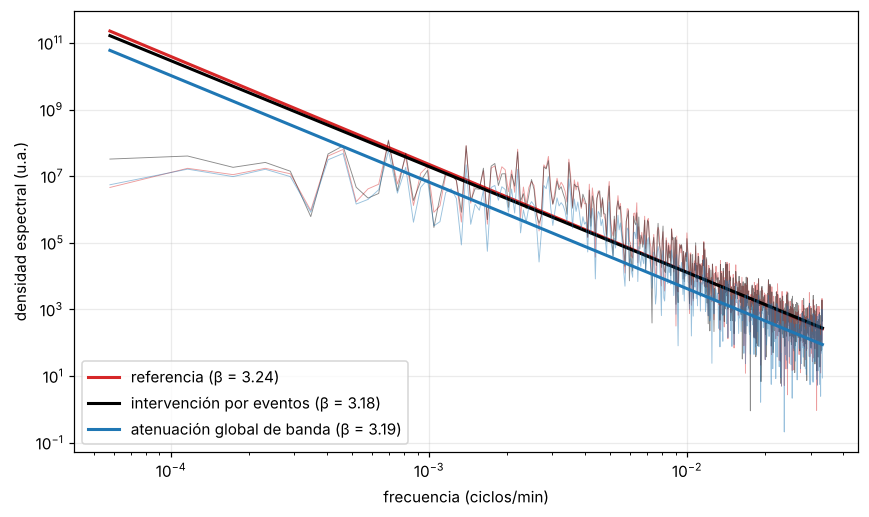

β periodograma: referencia 3.24 → eventos 3.18; global 3.19


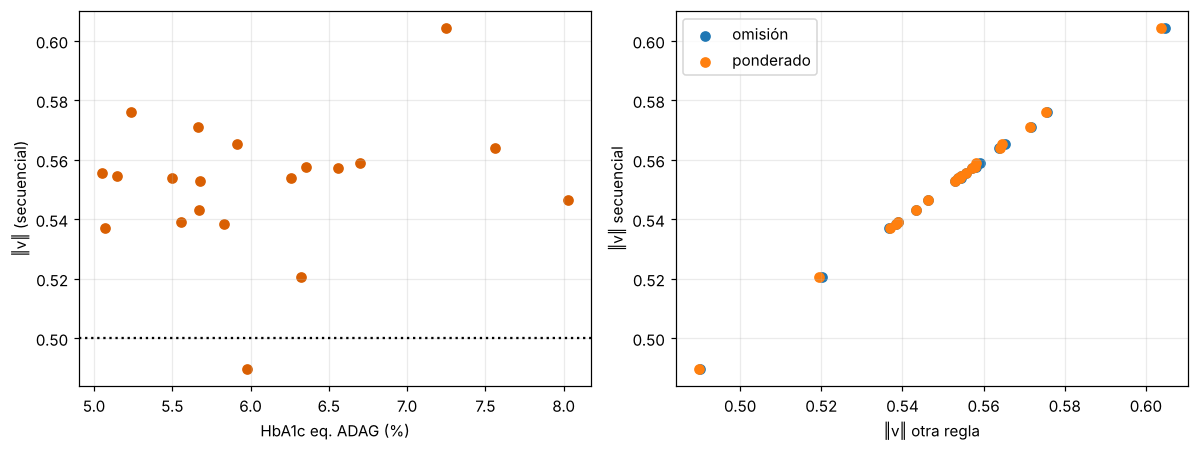

r(‖v‖, HbA1c) = 0.19; concordancia entre reglas (r medio) = 1.00


In [10]:
def beta_glob(y):
    return espectral.beta_banda_completa(y)

def transformada(nombre):
    rng = np.random.default_rng(42)
    if nombre == "S → ruido blanco": return rng.normal(0, s.std(), N)
    if nombre == "S = 0": return np.zeros(N)
    if nombre == "S con fase aleatorizada":
        F = np.fft.rfft(s); fase = np.exp(1j * rng.uniform(0, 2 * np.pi, len(F))); fase[0] = 1
        return np.fft.irfft(np.abs(F) * fase, n=N)
    return s

filas = []
for nom in ["Referencia (S original)", "S → ruido blanco", "S = 0", "S con fase aleatorizada"]:
    y = sdde.simular(g, s=transformada(nom), ruido=ruido, **p); r = iv.resumen(y)
    filas.append({"Acción sobre S(t)": nom, "‖v‖": ordinal.norma_estacionaria(y), "β": beta_glob(y), "A1c eq.": r["A1c"], "TIR": r["TIR"]})
t64 = pd.DataFrame(filas); t64.round(3).to_csv(OUT / "tabla_6_4_transformaciones.csv", index=False); display(t64.round(3))

y_glob = iv.simular_intervencion(g, p, s - 0.5 * s_b, ruido=ruido)
print(f"β (Welch, banda completa): referencia {beta_glob(R.g_referencia):.2f} → intervención por eventos "
      f"{beta_glob(R.g_intervenida):.2f}; atenuación global de la banda {beta_glob(y_glob):.2f}")

# Figura 6.11 — periodograma de la glucosa con las tres pendientes (ajuste log–log en toda la banda)
fig, ax = plt.subplots(figsize=(8, 4.8))
for y, col, nom in ((R.g_referencia, "#d62728", "referencia"), (R.g_intervenida, "k", "intervención por eventos"),
                    (y_glob, "#1f77b4", "atenuación global de banda")):
    f_ = np.fft.rfftfreq(N, d=15.0); P_ = np.abs(np.fft.rfft(y - y.mean())) ** 2; k_ = f_ > 0
    bta = espectral.beta_periodograma(y - y.mean())
    ax.loglog(f_[k_], P_[k_], color=col, lw=.6, alpha=.45)
    c0 = np.polyfit(np.log10(f_[k_]), np.log10(P_[k_]), 1)
    ax.loglog(f_[k_], 10 ** np.polyval(c0, np.log10(f_[k_])), color=col, lw=2, label=f"{nom} (β = {bta:.2f})")
ax.set(xlabel="frecuencia (ciclos/min)", ylabel="densidad espectral (u.a.)"); ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(OUT / "figura_6_11_psd_intervencion.png", dpi=200); plt.show()
print("β periodograma: referencia %.2f → eventos %.2f; global %.2f" % tuple(espectral.beta_periodograma(y - y.mean()) for y in (R.g_referencia, R.g_intervenida, y_glob)))

vv = pd.DataFrame([dict(Sujeto=i, A1c=iv.a1c_adag(sdde.simular(datos.cargar_cgm("DBT2", i, N), **datos.parametros("DBT2", i)).mean()),
                        **{r: ordinal.norma_estacionaria(sdde.simular(datos.cargar_cgm("DBT2", i, N), **datos.parametros("DBT2", i)), r)
                           for r in ("omision", "secuencial", "ponderado")}) for i in datos.IDS_DBT2])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(vv.A1c, vv.secuencial, color="#d95f02"); ax[0].axhline(.5, color="k", ls=":"); ax[0].set(xlabel="HbA1c eq. ADAG (%)", ylabel="‖v‖ (secuencial)")
ax[1].scatter(vv.omision, vv.secuencial, label="omisión"); ax[1].scatter(vv.ponderado, vv.secuencial, label="ponderado"); ax[1].legend()
ax[1].set(xlabel="‖v‖ otra regla", ylabel="‖v‖ secuencial")
fig.tight_layout(); fig.savefig(OUT / "figura_6_12_norma_v.png", dpi=200); plt.show()
print(f"r(‖v‖, HbA1c) = {stats.pearsonr(vv.A1c, vv.secuencial)[0]:.2f}; concordancia entre reglas (r medio) = "
      f"{np.mean([stats.pearsonr(vv.secuencial, vv[c])[0] for c in ('omision', 'ponderado')]):.2f}")

## Verificación de las cifras del capítulo
`✔` indica coincidencia con el valor del texto de la tesis al redondeo con que se informa.

In [11]:
def fila(dato, tesis, obtenido, dec):
    o = round(float(obtenido), dec)
    return dict(Dato=dato, Tesis=tesis, Reproducido=o, Coincide="✔" if abs(o - tesis) < 1e-9 else "✘")

CIFRAS_6 = [
    ("Sujeto 5: Ḡ medida (mg/dL)", g.mean(), 1), ("Sujeto 5: TIR medida (%)", iv.resumen(g)["TIR"], 1),
    ("Sujeto 5: HbA1c eq. medida (%)", iv.a1c_adag(g.mean()), 2), ("Sujeto 5: GMI medida (%)", iv.gmi(g.mean()), 2),
    ("Sujeto 5: ρ referencia vs señal medida", np.corrcoef(g_ref, g)[0, 1], 2),
    ("Sujeto 5: Ḡ referencia (mg/dL)", ref["G_media"], 1), ("Sujeto 5: TIR referencia (%)", ref["TIR"], 1),
    ("Sujeto 5: HbA1c eq. referencia (%)", ref["A1c"], 2), ("Sujeto 5: GMI referencia (%)", ref["GMI"], 2),
    ("Sujeto 5: Ḡ intervención (mg/dL)", inter["G_media"], 1), ("Sujeto 5: TIR intervención (%)", inter["TIR"], 1),
    ("Sujeto 5: TBR intervención (%)", inter["TBR"], 1), ("Sujeto 5: HbA1c eq. intervención (%)", inter["A1c"], 2),
    ("Sujeto 5: GMI intervención (%)", inter["GMI"], 2), ("Sujeto 5: eventos", len(eventos), 0),
    ("Sujeto 5: eventos modificados", np.sum(R.rho < 0.99), 0),
    ("Sujeto 5: energía posprandial de referencia (u.a.)", R.energia_ref.sum(), 1),
    ("Sujeto 5: energía posprandial final (u.a.)", R.energia_final.sum(), 1),
    ("Sujeto 5: energía conservada (%)", 100 * R.energia_final.sum() / R.energia_ref.sum(), 0),
    ("Sujeto 5: ‖v‖ referencia", v_ref, 3), ("Sujeto 5: ‖v‖ intervención", v_int, 3),
    ("Población: reducción media HbA1c eq.", (t63.A1c_ref - t63.A1c_int).mean(), 2),
    ("Población: sujetos ≤ 5,5 %", np.sum(t63.A1c_int <= 5.5), 0),
    ("Población: sujetos admisibles", np.sum(t63.admisible == "sí"), 0),
    ("β referencia (Fig. 6.11)", espectral.beta_periodograma(R.g_referencia - R.g_referencia.mean()), 2),
    ("β intervención por eventos", espectral.beta_periodograma(R.g_intervenida - R.g_intervenida.mean()), 2),
    ("β atenuación global", espectral.beta_periodograma(y_glob - y_glob.mean()), 2),
    *[(f"Tabla 6.4 {r['Acción sobre S(t)']}: ‖v‖", r["‖v‖"], 3) for _, r in t64.iterrows()],
    *[(f"Tabla 6.4 {r['Acción sobre S(t)']}: TIR", r["TIR"], 0) for _, r in t64.iterrows()],
    ("r(‖v‖, HbA1c eq.) en 20 sujetos", stats.pearsonr(vv.A1c, vv.secuencial)[0], 2),
    ("Concordancia entre reglas de empates", np.mean([stats.pearsonr(vv.secuencial, vv[c])[0] for c in ("omision", "ponderado")]), 2),
    ("Sujetos con ‖v‖ > 0,50", np.sum(vv.secuencial > .5), 0),
]
TESIS_6 = {  # cifras del texto del capítulo
    'Sujeto 5: Ḡ medida (mg/dL)': 161.3,
    'Sujeto 5: TIR medida (%)': 70.5,
    'Sujeto 5: HbA1c eq. medida (%)': 7.25,
    'Sujeto 5: GMI medida (%)': 7.17,
    'Sujeto 5: ρ referencia vs señal medida': 0.84,
    'Sujeto 5: Ḡ referencia (mg/dL)': 161.3,
    'Sujeto 5: TIR referencia (%)': 72.9,
    'Sujeto 5: HbA1c eq. referencia (%)': 7.25,
    'Sujeto 5: GMI referencia (%)': 7.17,
    'Sujeto 5: Ḡ intervención (mg/dL)': 148.1,
    'Sujeto 5: TIR intervención (%)': 80.6,
    'Sujeto 5: TBR intervención (%)': 1.1,
    'Sujeto 5: HbA1c eq. intervención (%)': 6.79,
    'Sujeto 5: GMI intervención (%)': 6.85,
    'Sujeto 5: eventos': 28.0,
    'Sujeto 5: eventos modificados': 28.0,
    'Sujeto 5: energía posprandial de referencia (u.a.)': 22.4,
    'Sujeto 5: energía posprandial final (u.a.)': 15.6,
    'Sujeto 5: energía conservada (%)': 70.0,
    'Sujeto 5: ‖v‖ referencia': 0.604,
    'Sujeto 5: ‖v‖ intervención': 0.607,
    'Población: reducción media HbA1c eq.': 0.38,
    'Población: sujetos ≤ 5,5 %': 10.0,
    'Población: sujetos admisibles': 7.0,
    'β referencia (Fig. 6.11)': 3.24,
    'β intervención por eventos': 3.18,
    'β atenuación global': 3.19,
    'Tabla 6.4 Referencia (S original): ‖v‖': 0.604,
    'Tabla 6.4 S → ruido blanco: ‖v‖': 0.452,
    'Tabla 6.4 S = 0: ‖v‖': 0.444,
    'Tabla 6.4 S con fase aleatorizada: ‖v‖': 0.595,
    'Tabla 6.4 Referencia (S original): TIR': 73.0,
    'Tabla 6.4 S → ruido blanco: TIR': 53.0,
    'Tabla 6.4 S = 0: TIR': 23.0,
    'Tabla 6.4 S con fase aleatorizada: TIR': 24.0,
    'r(‖v‖, HbA1c eq.) en 20 sujetos': 0.19,
    'Concordancia entre reglas de empates': 1.0,
    'Sujetos con ‖v‖ > 0,50': 19.0,
}
ver = pd.DataFrame([fila(d, TESIS_6[d], o, k) for d, o, k in CIFRAS_6])
ver.to_csv(OUT / "verificacion_cap6.csv", index=False); ver

,Dato,Tesis,Reproducido,Coincide
0,Sujeto 5: Ḡ medida (mg/dL),161.300,161.300,✔
1,Sujeto 5: TIR medida (%),70.500,70.500,✔
2,Sujeto 5: HbA1c eq. medida (%),7.250,7.250,✔
3,Sujeto 5: GMI medida (%),7.170,7.170,✔
4,Sujeto 5: ρ referencia vs señal medida,0.840,0.840,✔
5,Sujeto 5: Ḡ referencia (mg/dL),161.300,161.300,✔
6,Sujeto 5: TIR referencia (%),72.900,72.900,✔
7,Sujeto 5: HbA1c eq. referencia (%),7.250,7.250,✔
8,Sujeto 5: GMI referencia (%),7.170,7.170,✔
9,Sujeto 5: Ḡ intervención (mg/dL),148.100,148.100,✔
